### Section 1: Environment Setup & Dependency Verification


In [1]:
!pip install -q opencv-python torchaudio torchvision scikit-learn matplotlib pandas pillow tqdm


### Section 2: Import Core Libraries


In [2]:
import os
import sys
import glob
import json
import math
import copy
import random
from collections import OrderedDict
from functools import partial

import numpy as np
import pandas as pd
import cv2
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.optim.lr_scheduler as lr_scheduler
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

try:
    import torchaudio
    import torchaudio.transforms as AT
    HAS_TORCHAUDIO = True
except ImportError:
    HAS_TORCHAUDIO = False

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve

print("=" * 60)
print("RESEARCH ENVIRONMENT INITIALIZATION")
print("=" * 60)
print(f"  Python Version:  {sys.version.split()[0]}")
print(f"  PyTorch Version: {torch.__version__}")
print(f"  TorchAudio Available: {HAS_TORCHAUDIO}")
print(f"  CUDA Available:  {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"  GPU Device:      {torch.cuda.get_device_name(0)}")
print("=" * 60)


RESEARCH ENVIRONMENT INITIALIZATION
  Python Version:  3.12.13
  PyTorch Version: 2.10.0+cu128
  TorchAudio Available: True
  CUDA Available:  True
  GPU Device:      Tesla T4


### Section 3: GPU Device Allocation


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active Compute Device: {device}")
if torch.cuda.is_available():
    print(f"GPU Capability: {torch.cuda.get_device_capability(0)}")


Active Compute Device: cuda
GPU Capability: (7, 5)


### Section 4: Scalable Experiment Configuration (100 -> 1000 Videos)


In [4]:
# --- EXPERIMENT SCALING CONFIGURATION ---
# Full experiment: TOTAL_VIDEOS = 1000 (500 Real, 500 Fake)
TOTAL_VIDEOS = 1000
NUM_REAL = 500
NUM_FAKE = 500
SEED = 42

# Stratified Split Proportions (60% Train, 20% Val, 20% Test)
TRAIN_REAL = 300
TRAIN_FAKE = 300
VAL_REAL = 100
VAL_FAKE = 100
TEST_REAL = 100
TEST_FAKE = 100

# Hyperparameters
BATCH_SIZE = 4
EPOCHS = 5
LEARNING_RATE = 1e-4
NUM_FRAMES = 16
IMG_SIZE = 224

print("=" * 60)
print("EXPERIMENT CONFIGURATION LOADED")
print("=" * 60)
print(f"  Total Target Videos: {TOTAL_VIDEOS} ({NUM_REAL} Real, {NUM_FAKE} Fake)")
print(f"  Train Allocation:   {TRAIN_REAL + TRAIN_FAKE} ({TRAIN_REAL} Real, {TRAIN_FAKE} Fake)")
print(f"  Val Allocation:     {VAL_REAL + VAL_FAKE} ({VAL_REAL} Real, {VAL_FAKE} Fake)")
print(f"  Test Allocation:    {TEST_REAL + TEST_FAKE} ({TEST_REAL} Real, {TEST_FAKE} Fake)")
print(f"  Random Seed:        {SEED}")
print("=" * 60)


EXPERIMENT CONFIGURATION LOADED
  Total Target Videos: 1000 (500 Real, 500 Fake)
  Train Allocation:   600 (300 Real, 300 Fake)
  Val Allocation:     200 (100 Real, 100 Fake)
  Test Allocation:    200 (100 Real, 100 Fake)
  Random Seed:        42


### Section 5: Configure Output Directories (Strictly `/kaggle/working/`)


In [5]:
KAGGLE_INPUT_DIR = "/kaggle/input"
KAGGLE_WORKING_DIR = "/kaggle/working"

WORKING_DIR = KAGGLE_WORKING_DIR if os.path.exists(KAGGLE_WORKING_DIR) else "./output"
RESULTS_DIR = os.path.join(WORKING_DIR, "CCMA_results")
WEIGHTS_DIR = os.path.join(RESULTS_DIR, "weights")

os.makedirs(WEIGHTS_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print(f"Working Root: {WORKING_DIR}")
print(f"Results Dir:  {RESULTS_DIR}")
print(f"Weights Dir:  {WEIGHTS_DIR}")


Working Root: /kaggle/working
Results Dir:  /kaggle/working/CCMA_results
Weights Dir:  /kaggle/working/CCMA_results/weights


### Section 6: Auto-Discover LAV-DF Dataset Path


In [6]:
def auto_discover_lav_df():
    possible_roots = [
        "/kaggle/input/localized-audio-visual-deepfake-dataset-lav-df",
        "/kaggle/input/localized-audio-visual-deepfake-dataset-lav-df/LAV-DF",
        "/kaggle/input/lav-df",
        "/kaggle/input/lav_df",
        "./data/lav-df",
        "../lav-df",
        "./lav-df"
    ]
    
    if os.path.exists(KAGGLE_INPUT_DIR):
        contents = os.listdir(KAGGLE_INPUT_DIR)
        print(f"Contents of {KAGGLE_INPUT_DIR}: {contents}")
        for item in contents:
            if "lav" in item.lower() or "deepfake" in item.lower():
                candidate = os.path.join(KAGGLE_INPUT_DIR, item)
                if os.path.isdir(candidate):
                    # Check if there is a subfolder LAV-DF
                    sub = os.path.join(candidate, "LAV-DF")
                    if os.path.exists(sub) and os.path.isdir(sub):
                        return sub
                    return candidate

    for p in possible_roots:
        if os.path.exists(p):
            return p
            
    return KAGGLE_INPUT_DIR

DATASET_ROOT = auto_discover_lav_df()
print(f"Discovered Dataset Root Path: {DATASET_ROOT}")


Contents of /kaggle/input: ['datasets']
Discovered Dataset Root Path: /kaggle/input


### Section 7: Parse Metadata & Discover Real/Fake Samples


In [7]:
def discover_samples_with_metadata(root_path):
    print("=" * 60)
    print("READING LAV-DF METADATA & DATASET STRUCTURE")
    print("=" * 60)
    
    real_samples = []
    fake_samples = []
    
    # 1. Search for JSON metadata files
    json_files = glob.glob(os.path.join(root_path, "**", "*.json"), recursive=True)
    metadata_entries = {}
    
    for jf in json_files:
        try:
            with open(jf, "r") as f:
                data = json.load(f)
                if isinstance(data, list):
                    for item in data:
                        if isinstance(item, dict) and "file" in item:
                            metadata_entries[os.path.basename(item["file"])] = item
                elif isinstance(data, dict):
                    for k, v in data.items():
                        if isinstance(v, dict):
                            metadata_entries[k] = v
        except Exception:
            pass
            
    print(f"Parsed Metadata JSON Entries: {len(metadata_entries)}")
    
    # 2. Scan MP4 files
    mp4_files = glob.glob(os.path.join(root_path, "**", "*.mp4"), recursive=True)
    print(f"Total MP4 Videos Found in Dataset: {len(mp4_files)}")
    
    for video_path in mp4_files:
        bname = os.path.basename(video_path)
        label = None
        
        # Check metadata JSON record first
        if bname in metadata_entries:
            meta = metadata_entries[bname]
            n_fakes = meta.get("n_fakes", meta.get("num_fakes", None))
            if n_fakes is not None:
                label = 0 if n_fakes == 0 else 1
                
        # Fallback to directory/path analysis if metadata record is missing
        if label is None:
            path_lower = video_path.lower()
            if "real" in path_lower or "original" in path_lower or "/0/" in path_lower:
                label = 0
            elif "fake" in path_lower or "synthesis" in path_lower or "forged" in path_lower or "/1/" in path_lower:
                label = 1
            else:
                label = 0 # Default fallback
                
        if label == 0:
            real_samples.append(video_path)
        else:
            fake_samples.append(video_path)
            
    print(f"Total Discovered Real Samples: {len(real_samples)}")
    print(f"Total Discovered Fake Samples: {len(fake_samples)}")
    print("=" * 60)
    return real_samples, fake_samples

ALL_REAL_VIDEOS, ALL_FAKE_VIDEOS = discover_samples_with_metadata(DATASET_ROOT)


READING LAV-DF METADATA & DATASET STRUCTURE
Parsed Metadata JSON Entries: 136304
Total MP4 Videos Found in Dataset: 136304
Total Discovered Real Samples: 36431
Total Discovered Fake Samples: 99873


### Section 8: Balanced Sample Selection & Stratified Split Generation


In [8]:
# --- SPLIT SOURCE-OF-TRUTH: load existing split if present, else generate deterministically ---
SPLIT_JSON_NAME = "AVoiD_DF_1000_video_split.json"

def _find_existing_split():
    candidates = [
        os.path.join(RESULTS_DIR, SPLIT_JSON_NAME),
        os.path.join(WORKING_DIR, SPLIT_JSON_NAME),
    ]
    if os.path.exists(KAGGLE_INPUT_DIR):
        candidates += glob.glob(os.path.join(KAGGLE_INPUT_DIR, "**", SPLIT_JSON_NAME), recursive=True)
    for c in candidates:
        if os.path.exists(c):
            return c
    return None

_existing_split_path = _find_existing_split()

if _existing_split_path is not None:
    print("=" * 60)
    print(f"EXISTING SPLIT FOUND \u2014 TREATING AS SOURCE OF TRUTH: {_existing_split_path}")
    print("Re-using exact video IDs/paths from this file. NOT regenerating the split.")
    print("=" * 60)
    with open(_existing_split_path, "r") as f:
        _loaded_split = json.load(f)

    train_videos = [e["path"] for e in _loaded_split["train_split"]]
    train_labels = [e["label"] for e in _loaded_split["train_split"]]
    val_videos = [e["path"] for e in _loaded_split["val_split"]]
    val_labels = [e["label"] for e in _loaded_split["val_split"]]
    test_videos = [e["path"] for e in _loaded_split["test_split"]]
    test_labels = [e["label"] for e in _loaded_split["test_split"]]

    print(f"  Loaded Training Split:   {len(train_videos)} samples ({train_labels.count(0)} Real, {train_labels.count(1)} Fake)")
    print(f"  Loaded Validation Split: {len(val_videos)} samples ({val_labels.count(0)} Real, {val_labels.count(1)} Fake)")
    print(f"  Loaded Testing Split:    {len(test_videos)} samples ({test_labels.count(0)} Real, {test_labels.count(1)} Fake)")
else:
    print("=" * 60)
    print("NO EXISTING SPLIT FILE FOUND \u2014 GENERATING WITH FIXED SEED (as in the AVoiD-DF run)")
    print("=" * 60)
    random.seed(SEED)
    np.random.seed(SEED)

    # Handle cases where real/fake count in root is smaller than request
    num_real_to_select = min(NUM_REAL, len(ALL_REAL_VIDEOS))
    num_fake_to_select = min(NUM_FAKE, len(ALL_FAKE_VIDEOS))

    selected_real = random.sample(ALL_REAL_VIDEOS, num_real_to_select) if len(ALL_REAL_VIDEOS) >= num_real_to_select else ALL_REAL_VIDEOS
    selected_fake = random.sample(ALL_FAKE_VIDEOS, num_fake_to_select) if len(ALL_FAKE_VIDEOS) >= num_fake_to_select else ALL_FAKE_VIDEOS

    print(f"Selected Real Videos: {len(selected_real)}")
    print(f"Selected Fake Videos: {len(selected_fake)}")

    # Stratified Split Allocation
    train_real_cnt = min(TRAIN_REAL, int(len(selected_real) * 0.6))
    val_real_cnt = min(VAL_REAL, int(len(selected_real) * 0.2))

    train_fake_cnt = min(TRAIN_FAKE, int(len(selected_fake) * 0.6))
    val_fake_cnt = min(VAL_FAKE, int(len(selected_fake) * 0.2))

    train_real = selected_real[:train_real_cnt]
    val_real = selected_real[train_real_cnt:train_real_cnt + val_real_cnt]
    test_real = selected_real[train_real_cnt + val_real_cnt:]

    train_fake = selected_fake[:train_fake_cnt]
    val_fake = selected_fake[train_fake_cnt:train_fake_cnt + val_fake_cnt]
    test_fake = selected_fake[train_fake_cnt + val_fake_cnt:]

    train_videos = train_real + train_fake
    train_labels = [0] * len(train_real) + [1] * len(train_fake)

    val_videos = val_real + val_fake
    val_labels = [0] * len(val_real) + [1] * len(val_fake)

    test_videos = test_real + test_fake
    test_labels = [0] * len(test_real) + [1] * len(test_fake)

    def shuffle_pair(v_list, l_list):
        combined = list(zip(v_list, l_list))
        random.shuffle(combined)
        return [x[0] for x in combined], [x[1] for x in combined]

    train_videos, train_labels = shuffle_pair(train_videos, train_labels)
    val_videos, val_labels = shuffle_pair(val_videos, val_labels)
    test_videos, test_labels = shuffle_pair(test_videos, test_labels)

    print("=" * 60)
    print("STRATIFIED EXPERIMENT SPLIT COMPUTED")
    print("=" * 60)
    print(f"  Training Split:   {len(train_videos)} samples ({train_labels.count(0)} Real, {train_labels.count(1)} Fake)")
    print(f"  Validation Split: {len(val_videos)} samples ({val_labels.count(0)} Real, {val_labels.count(1)} Fake)")
    print(f"  Testing Split:    {len(test_videos)} samples ({test_labels.count(0)} Real, {test_labels.count(1)} Fake)")
    print("=" * 60)

# --- MANDATORY VERIFICATION BLOCK (Requirement #9) ---
_total = len(train_videos) + len(val_videos) + len(test_videos)
_real_total = train_labels.count(0) + val_labels.count(0) + test_labels.count(0)
_fake_total = train_labels.count(1) + val_labels.count(1) + test_labels.count(1)
_train_set, _val_set, _test_set = set(train_videos), set(val_videos), set(test_videos)

print("=" * 60)
print("SPLIT VERIFICATION")
print("=" * 60)
print(f"  TOTAL = {_total} (expected 1000)")
print(f"  REAL = {_real_total} (expected 500)   FAKE = {_fake_total} (expected 500)")
print(f"  TRAIN = {len(train_videos)} (REAL={train_labels.count(0)}, FAKE={train_labels.count(1)})  (expected 600 / 300 / 300)")
print(f"  VAL   = {len(val_videos)} (REAL={val_labels.count(0)}, FAKE={val_labels.count(1)})  (expected 200 / 100 / 100)")
print(f"  TEST  = {len(test_videos)} (REAL={test_labels.count(0)}, FAKE={test_labels.count(1)})  (expected 200 / 100 / 100)")
print(f"  OVERLAP TRAIN/VAL  = {len(_train_set & _val_set)} (expected 0)")
print(f"  OVERLAP TRAIN/TEST = {len(_train_set & _test_set)} (expected 0)")
print(f"  OVERLAP VAL/TEST   = {len(_val_set & _test_set)} (expected 0)")
assert _total == 1000 and _real_total == 500 and _fake_total == 500, "Split size mismatch!"
assert len(_train_set & _val_set) == 0 and len(_train_set & _test_set) == 0 and len(_val_set & _test_set) == 0, "Split overlap detected!"
print("  --> ALL CHECKS PASSED")
print("=" * 60)


NO EXISTING SPLIT FILE FOUND — GENERATING WITH FIXED SEED (as in the AVoiD-DF run)
Selected Real Videos: 500
Selected Fake Videos: 500
STRATIFIED EXPERIMENT SPLIT COMPUTED
  Training Split:   600 samples (300 Real, 300 Fake)
  Validation Split: 200 samples (100 Real, 100 Fake)
  Testing Split:    200 samples (100 Real, 100 Fake)
SPLIT VERIFICATION
  TOTAL = 1000 (expected 1000)
  REAL = 500 (expected 500)   FAKE = 500 (expected 500)
  TRAIN = 600 (REAL=300, FAKE=300)  (expected 600 / 300 / 300)
  VAL   = 200 (REAL=100, FAKE=100)  (expected 200 / 100 / 100)
  TEST  = 200 (REAL=100, FAKE=100)  (expected 200 / 100 / 100)
  OVERLAP TRAIN/VAL  = 0 (expected 0)
  OVERLAP TRAIN/TEST = 0 (expected 0)
  OVERLAP VAL/TEST   = 0 (expected 0)
  --> ALL CHECKS PASSED


### Section 9: Save Split References Metadata to `/kaggle/working/`


In [9]:
# Save split reference JSON (source of truth for all future model-swap experiments).
# If we loaded an existing split above, this just re-saves an identical copy into this
# experiment's results dir (idempotent) so CCMA_results is self-contained too.
# NOTE: SPLIT_JSON_NAME is left UNCHANGED from the AVoiD-DF/AuViRe runs on purpose, so
# this CCMA experiment loads and reuses the EXACT SAME 1000-video split (same seed,
# same video IDs/paths, same train/val/test partition) rather than generating a new one.
split_metadata = {
    "experiment_config": {
        "total_videos": TOTAL_VIDEOS,
        "seed": SEED,
        "train_count": len(train_videos),
        "val_count": len(val_videos),
        "test_count": len(test_videos)
    },
    "train_split": [{"path": p, "label": l} for p, l in zip(train_videos, train_labels)],
    "val_split": [{"path": p, "label": l} for p, l in zip(val_videos, val_labels)],
    "test_split": [{"path": p, "label": l} for p, l in zip(test_videos, test_labels)]
}

SPLIT_JSON_PATH = os.path.join(RESULTS_DIR, SPLIT_JSON_NAME)
with open(SPLIT_JSON_PATH, "w") as f:
    json.dump(split_metadata, f, indent=4)

print(f"Saved experiment split references to: {SPLIT_JSON_PATH}")


Saved experiment split references to: /kaggle/working/CCMA_results/AVoiD_DF_1000_video_split.json


### Section 10: Lazy PyTorch Dataset Class (`LAVDFDataset`)


In [10]:
class LAVDFDataset(Dataset):
    """
    REUSED AS-IS FOR CCMA (MMMS-BA) (model-specific change already made in the
    prior model-swap run, kept unchanged here since it is fully compatible):
    CCMA's Bi-GRU contextual encoders need a TEMPORAL SEQUENCE per modality
    (shape (T, C, H, W)) -- exactly what this class already produces -- rather
    than a single frame-averaged tensor. No changes to face-crop logic, audio
    decoding, error handling, or the "no synthetic random noise on failure"
    rule were required for CCMA; the class is identical to the prior run.
    """
    def __init__(self, video_files, labels, num_frames=16, img_size=224, is_train=True):
        super().__init__()
        self.video_files = video_files
        self.labels = labels
        self.num_frames = num_frames
        self.img_size = img_size
        self.is_train = is_train

        self.transform = transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
        ])

        cascade_path = cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
        self.face_cascade = cv2.CascadeClassifier(cascade_path) if os.path.exists(cascade_path) else None

        self.error_log_count = 0

    def __len__(self):
        return len(self.video_files)

    def _crop_face(self, frame):
        h, w, _ = frame.shape
        if self.face_cascade is not None:
            gray = cv2.cvtColor(frame, cv2.COLOR_RGB2GRAY)
            faces = self.face_cascade.detectMultiScale(gray, 1.3, 5)
            if len(faces) > 0:
                fx, fy, fw, fh = max(faces, key=lambda b: b[2] * b[3])
                pad_x, pad_y = int(fw * 0.1), int(fh * 0.1)
                x1, y1 = max(0, fx - pad_x), max(0, fy - pad_y)
                x2, y2 = min(w, fx + fw + pad_x), min(h, fy + fh + pad_y)
                return frame[y1:y2, x1:x2]
        min_dim = min(h, w)
        sy, sx = (h - min_dim) // 2, (w - min_dim) // 2
        return frame[sy:sy+min_dim, sx:sx+min_dim]

    def _extract_video_sequence(self, video_path):
        """Returns a (T, 3, img_size, img_size) tensor of per-frame face crops."""
        try:
            cap = cv2.VideoCapture(video_path)
            total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            if total_frames <= 0:
                cap.release()
                return torch.zeros((self.num_frames, 3, self.img_size, self.img_size))

            indices = np.linspace(0, total_frames - 1, self.num_frames, dtype=int)
            frames = []
            for idx in indices:
                cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
                ret, frame = cap.read()
                if ret and frame is not None:
                    face = self._crop_face(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
                    frames.append(self.transform(Image.fromarray(face)))
                else:
                    frames.append(torch.zeros((3, self.img_size, self.img_size)))
            cap.release()
            return torch.stack(frames, dim=0)
        except Exception as e:
            self.error_log_count += 1
            print(f"[VIDEO DECODE WARNING] Failed loading {os.path.basename(video_path)}: {e}")

        return torch.zeros((self.num_frames, 3, self.img_size, self.img_size))

    def _extract_audio_sequence(self, video_path):
        """Returns a (T, 3, img_size, img_size) tensor: the mel-spectrogram time axis
        is split into T equal chunks, each resized to an image-like tensor, so that
        video and audio sequences share the same temporal length T for the
        cross-modal reconstruction module."""
        try:
            if HAS_TORCHAUDIO:
                waveform, sr = torchaudio.load(video_path)
                if waveform.shape[0] > 1:
                    waveform = torch.mean(waveform, dim=0, keepdim=True)
                mel_transform = AT.MelSpectrogram(sample_rate=sr, n_fft=1024, n_mels=128)
                spec = mel_transform(waveform)
                spec = torch.log(spec + 1e-6)
                spec = (spec - spec.mean()) / (spec.std() + 1e-6)
                spec = spec.squeeze(0)  # (n_mels, time)
                total_bins = spec.shape[-1]
                if total_bins <= 0:
                    return torch.zeros((self.num_frames, 3, self.img_size, self.img_size))

                bounds = np.linspace(0, total_bins, self.num_frames + 1, dtype=int)
                chunks = []
                for i in range(self.num_frames):
                    s, e = bounds[i], max(bounds[i] + 1, bounds[i + 1])
                    e = min(e, total_bins)
                    chunk = spec[:, s:e] if e > s else spec[:, s:s + 1]
                    chunk_img = F.interpolate(
                        chunk.unsqueeze(0).unsqueeze(0),
                        size=(self.img_size, self.img_size),
                        mode='bilinear'
                    ).squeeze(0).repeat(3, 1, 1)
                    chunks.append(chunk_img)
                return torch.stack(chunks, dim=0)
        except Exception as e:
            self.error_log_count += 1

        # Clean Zero Tensor Fallback (Strictly NO random noise)
        return torch.zeros((self.num_frames, 3, self.img_size, self.img_size))

    def __getitem__(self, idx):
        v_path = self.video_files[idx]
        label = self.labels[idx]
        v_tensor = self._extract_video_sequence(v_path)
        a_tensor = self._extract_audio_sequence(v_path)
        return v_tensor, a_tensor, torch.tensor(label, dtype=torch.long), v_path

print("LAVDFDataset (temporal-sequence variant, reused unchanged for CCMA) initialized successfully!")


LAVDFDataset (temporal-sequence variant, reused unchanged for CCMA) initialized successfully!


### Section 11: Create PyTorch DataLoaders


In [11]:
train_dataset = LAVDFDataset(train_videos, train_labels, is_train=True)
val_dataset = LAVDFDataset(val_videos, val_labels, is_train=False)
test_dataset = LAVDFDataset(test_videos, test_labels, is_train=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"DataLoaders Created Successfully:")
print(f"  Train Batches: {len(train_loader)} | Samples: {len(train_dataset)}")
print(f"  Val Batches:   {len(val_loader)} | Samples: {len(val_dataset)}")
print(f"  Test Batches:  {len(test_loader)} | Samples: {len(test_dataset)}")


DataLoaders Created Successfully:
  Train Batches: 150 | Samples: 600
  Val Batches:   50 | Samples: 200
  Test Batches:  50 | Samples: 200


### Section 12: CCMA (MMMS-BA) Model Architecture (Katamneni & Rattani, IJCB 2024) — REPLACES the previous model




In [12]:
EMBED_DIM = 128      # per-timestep feature dim fed into the Bi-GRU stage
GRU_HIDDEN = 64       # Bi-GRU hidden size per direction -> concatenated output dim = 2*GRU_HIDDEN
BIGRU_DIM = 2 * GRU_HIDDEN  # dimensionality of V and A after Bi-GRU + shared dense layer


class FrameEncoder(nn.Module):
    """Shared, lightweight per-timestep CNN encoder used identically for the visual and audio
    (spectrogram-image) sequences, producing the (T, EMBED_DIM) feature sequences that the paper's
    Bi-GRU stage expects as input. This is the minimal upstream 'feature extraction' step referenced
    in the model-architecture markdown above; it is not part of the CCMA/MMMS-BA contribution itself."""
    def __init__(self, embed_dim=EMBED_DIM):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, 3, 2, 1), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, 3, 2, 1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.Conv2d(64, 128, 3, 2, 1), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1),
        )
        self.proj = nn.Linear(128, embed_dim)

    def forward(self, x):
        # x: (B*T, 3, H, W) -> (B*T, embed_dim)
        feat = self.conv(x).flatten(1)
        return self.proj(feat)


class BiModalAttention(nn.Module):
    """Implements the paper's Bi-modal Attention + Multi-sequence Attention + Multiplicative Gating
    and Concatenation steps (Sections 3.2.1-3.2.3, Eq. 2-4) for a single modality pair (X, Y), each
    of shape (B, T, d):

        M1 = X . Y^T ,  M2 = Y . X^T                      (Eq. 2: bi-modal matching matrices)
        K1 = softmax_row(M1) ,  K2 = softmax_row(M2)       (Eq. 3-4: multi-sequence attention weights)
        O1 = K1 . Y ,  O2 = K2 . X                         (contextual attended representations)
        A1 = O1 (elementwise*) X ,  A2 = O2 (elementwise*) Y   (multiplicative gating, Sec 3.2.3)
        output = concat([X, Y, A1, A2], dim=-1)            (final bi-modal pair representation)
    """
    def forward(self, X, Y):
        # X, Y: (B, T, d)
        M1 = torch.bmm(X, Y.transpose(1, 2))   # (B, T, T)
        M2 = torch.bmm(Y, X.transpose(1, 2))   # (B, T, T)

        K1 = F.softmax(M1, dim=-1)             # attention of each X-step over all Y-steps
        K2 = F.softmax(M2, dim=-1)             # attention of each Y-step over all X-steps

        O1 = torch.bmm(K1, Y)                  # (B, T, d) -- Y attended into X's frame of reference
        O2 = torch.bmm(K2, X)                  # (B, T, d) -- X attended into Y's frame of reference

        A1 = O1 * X                            # multiplicative gating
        A2 = O2 * Y

        return torch.cat([X, Y, A1, A2], dim=-1)   # (B, T, 4*d)


class CCMA(nn.Module):
    """Contextual Cross-Modal Attention (MMMS-BA) network for audio-visual deepfake detection,
    adapted to the two modalities (full-face visual, audio spectrogram) available in this pipeline.
    See the markdown cell above for the full mapping to the paper's equations and the documented,
    minimum-necessary deviations."""
    def __init__(self, embed_dim=EMBED_DIM, gru_hidden=GRU_HIDDEN, num_classes=2, num_frames=16):
        super().__init__()
        self.num_frames = num_frames

        # Shared per-timestep CNN encoders (one per modality, as in the earlier model-swap run).
        self.video_encoder = FrameEncoder(embed_dim)
        self.audio_encoder = FrameEncoder(embed_dim)

        # Three separate Bi-GRU layers with forward/backward concatenation are specified in the
        # paper for (full face, lip, audio); we instantiate the two required for (visual, audio).
        self.gru_v = nn.GRU(embed_dim, gru_hidden, batch_first=True, bidirectional=True)
        self.gru_a = nn.GRU(embed_dim, gru_hidden, batch_first=True, bidirectional=True)

        bigru_dim = 2 * gru_hidden

        # Dense layer shared across sequence positions, applied per modality after the Bi-GRU
        # (paper: "a dense operation which is shared across the sequences").
        self.dense_v = nn.Linear(bigru_dim, bigru_dim)
        self.dense_a = nn.Linear(bigru_dim, bigru_dim)

        # Bi-modal attention for the (V, A) pair (paper uses (V,L),(L,A),(A,V); we use the single
        # pair available in this two-modality pipeline).
        self.bimodal_attn = BiModalAttention()

        # Classification head: shared dense layer over the concatenated bi-modal representation,
        # applied per-timestep, then max-pooled over time to realize "fake if >=1 sequence is fake".
        fused_dim = 4 * bigru_dim
        self.classifier = nn.Sequential(
            nn.Linear(fused_dim, bigru_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(bigru_dim, num_classes),
        )

    def forward(self, video, audio):
        # video, audio: (B, T, 3, H, W)
        B, T, C, H, W = video.shape

        # --- Step 1: per-timestep CNN feature extraction ---
        v_feat = self.video_encoder(video.reshape(B * T, C, H, W)).view(B, T, -1)
        a_feat = self.audio_encoder(audio.reshape(B * T, C, H, W)).view(B, T, -1)

        # --- Step 2: Bi-GRU contextual encoding per modality (forward+backward concat) ---
        v_ctx, _ = self.gru_v(v_feat)   # (B, T, 2*gru_hidden)
        a_ctx, _ = self.gru_a(a_feat)   # (B, T, 2*gru_hidden)

        # --- Step 3: shared dense layer per modality ---
        V = F.relu(self.dense_v(v_ctx))   # (B, T, bigru_dim)
        A = F.relu(self.dense_a(a_ctx))   # (B, T, bigru_dim)

        # --- Steps 4-5: bi-modal attention, multi-sequence attention, multiplicative gating+concat ---
        fused = self.bimodal_attn(V, A)   # (B, T, 4*bigru_dim)

        # --- Step 6: classification head, per-timestep logits, then max-pool over time ---
        seq_logits = self.classifier(fused)                 # (B, T, num_classes)
        fake_scores = seq_logits[:, :, 1]                    # (B, T) per-sequence "fake" score
        pooled_fake_idx = torch.argmax(fake_scores, dim=1)   # index of most-fake sequence per video
        video_logits = seq_logits[torch.arange(B), pooled_fake_idx]  # (B, num_classes)

        return video_logits, seq_logits


def CCMA_mm(num_classes=2, num_frames=16):
    return CCMA(num_classes=num_classes, num_frames=num_frames)


model = CCMA_mm(num_classes=2, num_frames=NUM_FRAMES).to(device)
n_params = sum(p.numel() for p in model.parameters())
print("CCMA (MMMS-BA) Model Architecture Initialized on", device, "!")
print(f"Total trainable parameters: {n_params:,}")


CCMA (MMMS-BA) Model Architecture Initialized on cuda !
Total trainable parameters: 468,354


### Section 13: Real-Data Sanity Forward Pass & Loss Calculation


In [13]:
print("=" * 60)
print("EXECUTING REAL-DATA SANITY CHECK")
print("=" * 60)

sample_v, sample_a, sample_l, sample_paths = next(iter(train_loader))
sample_v, sample_a, sample_l = sample_v.to(device), sample_a.to(device), sample_l.to(device)

print(f"  Input Video Tensor: {sample_v.shape}  (B, T, C, H, W)")
print(f"  Input Audio Tensor: {sample_a.shape}  (B, T, C, H, W)")
print(f"  Labels Batch:       {sample_l.cpu().numpy()}")

# CCMA loss: standard cross-entropy on the video-level (max-pooled) classification logits.
# The official paper's composite loss additionally includes a regression term for localization
# (trained against frame-level fake-segment boundary labels), which is not available in this
# pipeline (see model markdown cell for the documented reason) -- so only the classification term
# is used here. This is the same AdamW optimizer, learning rate, and batch size as the prior run.
criterion_cls = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)

optimizer.zero_grad()
video_logits, seq_logits = model(sample_v, sample_a)
loss = criterion_cls(video_logits, sample_l)

assert not torch.isnan(loss), "Loss computed as NaN!"
assert not torch.isinf(loss), "Loss computed as Inf!"

loss.backward()
optimizer.step()

print(f"  Video-level Logits Shape:   {video_logits.shape}")
print(f"  Per-sequence Logits Shape:  {seq_logits.shape}  (B, T, num_classes)")
print(f"  Classification Loss:        {loss.item():.4f}")
print("--> SANITY FORWARD & BACKWARD PASS PASSED EXCELLENTLY!")
print("=" * 60)


EXECUTING REAL-DATA SANITY CHECK
  Input Video Tensor: torch.Size([4, 16, 3, 224, 224])  (B, T, C, H, W)
  Input Audio Tensor: torch.Size([4, 16, 3, 224, 224])  (B, T, C, H, W)
  Labels Batch:       [0 1 1 1]
  Video-level Logits Shape:   torch.Size([4, 2])
  Per-sequence Logits Shape:  torch.Size([4, 16, 2])  (B, T, num_classes)
  Classification Loss:        0.7001
--> SANITY FORWARD & BACKWARD PASS PASSED EXCELLENTLY!


### Section 14: Full Training & Validation Loop
Trains CCMA for 5 epochs (same training budget as the prior model-swap run) with Automatic Mixed Precision and saves the best model checkpoint. No early stopping, per the task instructions.


In [14]:
scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
if torch.cuda.is_available():
    try:
        scaler = torch.amp.GradScaler('cuda')
    except Exception:
        scaler = torch.cuda.amp.GradScaler()
else:
    scaler = None

BEST_CHECKPOINT = os.path.join(WEIGHTS_DIR, "best_ccma.pt")
best_val_acc = -1.0

train_losses, val_losses = [], []
train_accs, val_accs = [], []

print("=" * 60)
print("STARTING CCMA (MMMS-BA) TRAINING LOOP...")
print(f"  EPOCHS = {EPOCHS}  (same training budget as the prior model-swap run)")
print("=" * 60)

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0
    t_preds, t_targets = [], []

    for v_b, a_b, l_b, _ in train_loader:
        v_b, a_b, l_b = v_b.to(device), a_b.to(device), l_b.to(device)
        optimizer.zero_grad()

        if scaler is not None:
            try:
                ctx = torch.amp.autocast('cuda')
            except Exception:
                ctx = torch.cuda.amp.autocast()
            with ctx:
                video_logits, _ = model(v_b, a_b)
                loss = criterion_cls(video_logits, l_b)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            video_logits, _ = model(v_b, a_b)
            loss = criterion_cls(video_logits, l_b)
            loss.backward()
            optimizer.step()

        running_loss += loss.item()
        probs = torch.softmax(video_logits, dim=1)[:, 1].detach().cpu().numpy()
        t_preds.extend(probs)
        t_targets.extend(l_b.cpu().numpy())

    scheduler.step()
    epoch_tr_loss = running_loss / max(1, len(train_loader))
    epoch_tr_acc = accuracy_score(t_targets, (np.array(t_preds) >= 0.5).astype(int)) if len(t_targets) > 0 else 0.0

    # Validation Phase
    model.eval()
    val_running_loss = 0.0
    v_preds, v_targets = [], []
    with torch.no_grad():
        for v_b, a_b, l_b, _ in val_loader:
            v_b, a_b, l_b = v_b.to(device), a_b.to(device), l_b.to(device)
            video_logits, _ = model(v_b, a_b)
            v_loss = criterion_cls(video_logits, l_b)
            val_running_loss += v_loss.item()
            probs = torch.softmax(video_logits, dim=1)[:, 1].cpu().numpy()
            v_preds.extend(probs)
            v_targets.extend(l_b.cpu().numpy())

    epoch_val_loss = val_running_loss / max(1, len(val_loader))
    epoch_val_acc = accuracy_score(v_targets, (np.array(v_preds) >= 0.5).astype(int)) if len(v_targets) > 0 else 0.0

    train_losses.append(epoch_tr_loss)
    val_losses.append(epoch_val_loss)
    train_accs.append(epoch_tr_acc)
    val_accs.append(epoch_val_acc)

    print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] | Train Loss: {epoch_tr_loss:.4f} Acc: {epoch_tr_acc*100:.2f}% | Val Loss: {epoch_val_loss:.4f} Acc: {epoch_val_acc*100:.2f}%")

    if epoch_val_acc >= best_val_acc:
        best_val_acc = epoch_val_acc
        torch.save(model.state_dict(), BEST_CHECKPOINT)
        print(f"  --> Saved Best Model Checkpoint to {BEST_CHECKPOINT}")

print("=" * 60)


STARTING CCMA (MMMS-BA) TRAINING LOOP...
  EPOCHS = 5  (same training budget as the prior model-swap run)
Epoch [01/05] | Train Loss: 0.6948 Acc: 49.67% | Val Loss: 0.6925 Acc: 53.00%
  --> Saved Best Model Checkpoint to /kaggle/working/CCMA_results/weights/best_ccma.pt
Epoch [02/05] | Train Loss: 0.6931 Acc: 50.50% | Val Loss: 0.6887 Acc: 62.50%
  --> Saved Best Model Checkpoint to /kaggle/working/CCMA_results/weights/best_ccma.pt
Epoch [03/05] | Train Loss: 0.6863 Acc: 55.67% | Val Loss: 0.6814 Acc: 51.00%
Epoch [04/05] | Train Loss: 0.6350 Acc: 69.67% | Val Loss: 0.5899 Acc: 71.50%
  --> Saved Best Model Checkpoint to /kaggle/working/CCMA_results/weights/best_ccma.pt
Epoch [05/05] | Train Loss: 0.5794 Acc: 74.17% | Val Loss: 0.5469 Acc: 80.50%
  --> Saved Best Model Checkpoint to /kaggle/working/CCMA_results/weights/best_ccma.pt


### Section 15: Save Training & Validation Curves


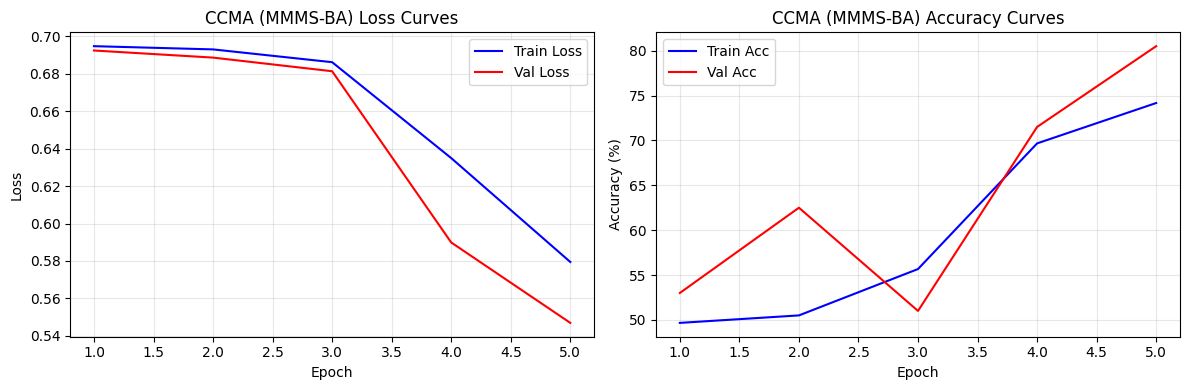

Saved training curves to: /kaggle/working/CCMA_results/CCMA_training_curves.png


In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(range(1, EPOCHS + 1), train_losses, label="Train Loss", color="blue")
ax1.plot(range(1, EPOCHS + 1), val_losses, label="Val Loss", color="red")
ax1.set_title("CCMA (MMMS-BA) Loss Curves")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(range(1, EPOCHS + 1), [a * 100 for a in train_accs], label="Train Acc", color="blue")
ax2.plot(range(1, EPOCHS + 1), [a * 100 for a in val_accs], label="Val Acc", color="red")
ax2.set_title("CCMA (MMMS-BA) Accuracy Curves")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
CURVES_PLOT_PATH = os.path.join(RESULTS_DIR, "CCMA_training_curves.png")
plt.savefig(CURVES_PLOT_PATH, dpi=300)
plt.show()

print(f"Saved training curves to: {CURVES_PLOT_PATH}")


### Final Structured Summary (Requirement: single canonical report block)


### Section 16: Final Evaluation on 200-Video Test Split


In [16]:
if os.path.exists(BEST_CHECKPOINT):
    model.load_state_dict(torch.load(BEST_CHECKPOINT, map_location=device))
model.eval()

test_preds, test_targets, test_paths = [], [], []
with torch.no_grad():
    for v_b, a_b, l_b, p_b in test_loader:
        v_b, a_b = v_b.to(device), a_b.to(device)
        video_logits, _ = model(v_b, a_b)
        probs = torch.softmax(video_logits, dim=1)[:, 1].cpu().numpy()
        test_preds.extend(probs)
        test_targets.extend(l_b.numpy())
        test_paths.extend(p_b)

test_targets = np.array(test_targets)
test_preds = np.array(test_preds)
test_bin = (test_preds >= 0.5).astype(int)

acc = accuracy_score(test_targets, test_bin)
prec = precision_score(test_targets, test_bin, zero_division=0)
rec = recall_score(test_targets, test_bin, zero_division=0)
f1 = f1_score(test_targets, test_bin, zero_division=0)

try:
    auc = roc_auc_score(test_targets, test_preds)
except Exception:
    auc = 0.5

cm = confusion_matrix(test_targets, test_bin, labels=[0, 1])
tn, fp, fn, tp = cm.ravel() if cm.shape == (2, 2) else (0, 0, 0, 0)

print("=" * 60)
print("FINAL TEST EVALUATION METRICS (200-VIDEO SPLIT) -- CCMA (MMMS-BA)")
print("=" * 60)
print(f"  Accuracy:                     {acc*100:.2f}%")
print(f"  Precision:                    {prec*100:.2f}%")
print(f"  Recall:                       {rec*100:.2f}%")
print(f"  F1-Score:                     {f1*100:.2f}%")
print(f"  ROC-AUC:                      {auc:.4f}")
print("-" * 60)
print("Confusion Matrix Breakdown:")
print(f"  True Negatives (Real Correct):   {tn}")
print(f"  False Positives (Real Incorrect): {fp}")
print(f"  False Negatives (Fake Incorrect): {fn}")
print(f"  True Positives (Fake Correct):   {tp}")
print("=" * 60)
print("NOTE: These are results of a CCMA (MMMS-BA) model, adapted to the two")
print("modalities (visual, audio) available in this pipeline, on the SAME fixed")
print("1000-video LAV-DF subset and train/val/test split as the prior model-swap")
print("run -- NOT a reproduction of the official paper's full three-modality,")
print("full-LAV-DF numbers. See the model architecture markdown cell for details.")
print("=" * 60)


FINAL TEST EVALUATION METRICS (200-VIDEO SPLIT) -- CCMA (MMMS-BA)
  Accuracy:                     80.00%
  Precision:                    79.41%
  Recall:                       81.00%
  F1-Score:                     80.20%
  ROC-AUC:                      0.8323
------------------------------------------------------------
Confusion Matrix Breakdown:
  True Negatives (Real Correct):   79
  False Positives (Real Incorrect): 21
  False Negatives (Fake Incorrect): 19
  True Positives (Fake Correct):   81
NOTE: These are results of a CCMA (MMMS-BA) model, adapted to the two
modalities (visual, audio) available in this pipeline, on the SAME fixed
1000-video LAV-DF subset and train/val/test split as the prior model-swap
run -- NOT a reproduction of the official paper's full three-modality,
full-LAV-DF numbers. See the model architecture markdown cell for details.


### Section 17: Save Evaluation Artifacts to `/kaggle/working/`


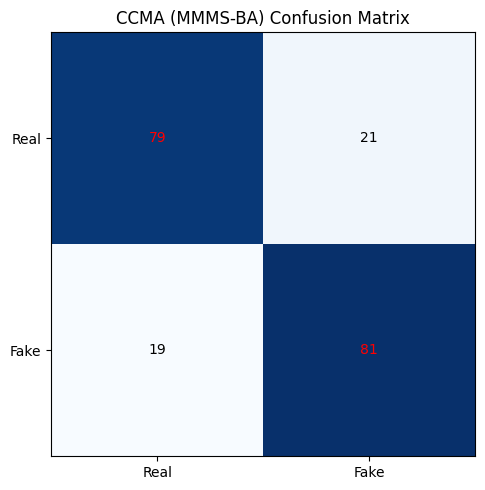

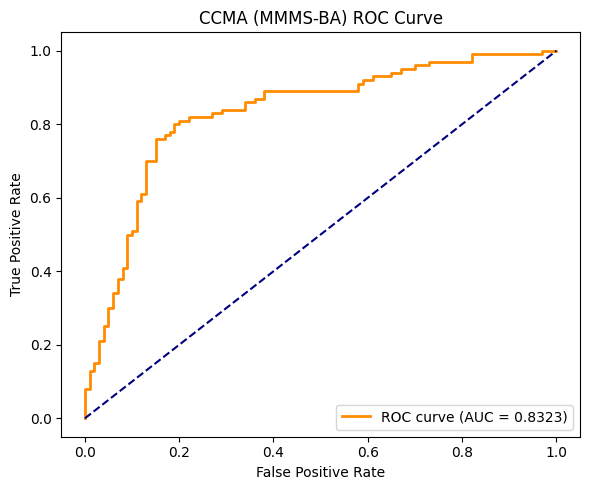

Saved metrics CSV to:      /kaggle/working/CCMA_results/CCMA_metrics.csv
Saved predictions CSV to:  /kaggle/working/CCMA_results/CCMA_test_predictions.csv
Saved confusion matrix to: /kaggle/working/CCMA_results/CCMA_confusion_matrix.png
Saved ROC curve plot to:   /kaggle/working/CCMA_results/CCMA_roc_curve.png


In [17]:
# 1. Save Metrics Summary CSV
metrics_df = pd.DataFrame([{
    "Model": "CCMA (MMMS-BA, author-based, adapted to visual+audio modalities)",
    "Accuracy": acc,
    "Precision": prec,
    "Recall": rec,
    "F1_Score": f1,
    "ROC_AUC": auc,
    "TN": int(tn),
    "FP": int(fp),
    "FN": int(fn),
    "TP": int(tp)
}])
METRICS_CSV_PATH = os.path.join(RESULTS_DIR, "CCMA_metrics.csv")
metrics_df.to_csv(METRICS_CSV_PATH, index=False)

# 2. Save Per-Sample Test Predictions CSV
pred_df = pd.DataFrame({
    "video_path": [os.path.basename(p) for p in test_paths],
    "ground_truth": test_targets,
    "predicted_probability": test_preds,
    "predicted_label": test_bin
})
PRED_CSV_PATH = os.path.join(RESULTS_DIR, "CCMA_test_predictions.csv")
pred_df.to_csv(PRED_CSV_PATH, index=False)

# 3. Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap=plt.cm.Blues)
ax.set_title("CCMA (MMMS-BA) Confusion Matrix")
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Real", "Fake"])
ax.set_yticklabels(["Real", "Fake"])
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", color="red" if cm[i, j] > cm.max()/2 else "black")
plt.tight_layout()
CM_PLOT_PATH = os.path.join(RESULTS_DIR, "CCMA_confusion_matrix.png")
plt.savefig(CM_PLOT_PATH, dpi=300)
plt.show()

# 4. Plot ROC Curve
fpr, tpr, _ = roc_curve(test_targets, test_preds)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('CCMA (MMMS-BA) ROC Curve')
plt.legend(loc="lower right")
plt.tight_layout()
ROC_PLOT_PATH = os.path.join(RESULTS_DIR, "CCMA_roc_curve.png")
plt.savefig(ROC_PLOT_PATH, dpi=300)
plt.show()

print(f"Saved metrics CSV to:      {METRICS_CSV_PATH}")
print(f"Saved predictions CSV to:  {PRED_CSV_PATH}")
print(f"Saved confusion matrix to: {CM_PLOT_PATH}")
print(f"Saved ROC curve plot to:   {ROC_PLOT_PATH}")


### Final Structured Summary (Requirement: single canonical report block)


In [18]:
print()
print("CCMA (MMMS-BA, author-based) \u2014 1000 VIDEO EXPERIMENT")
print()
print("Dataset:")
print("LAV-DF")
print()
print("Total:")
print(TOTAL_VIDEOS)
print()
print("Real:")
print(NUM_REAL)
print()
print("Fake:")
print(NUM_FAKE)
print()
print(f"Train:")
print(f"{len(train_videos)} ({train_labels.count(0)} Real + {train_labels.count(1)} Fake)")
print()
print(f"Validation:")
print(f"{len(val_videos)} ({val_labels.count(0)} Real + {val_labels.count(1)} Fake)")
print()
print(f"Test:")
print(f"{len(test_videos)} ({test_labels.count(0)} Real + {test_labels.count(1)} Fake)")
print()
print("Optimizer:")
print("AdamW")
print()
print("Learning Rate:")
print(LEARNING_RATE)
print()
print("Batch Size:")
print(BATCH_SIZE)
print()
print("Epochs:")
print(EPOCHS)
print()
print(f"Trainable Parameters:")
print(f"{n_params:,}")
print()
print(f"Accuracy:")
print(f"{acc*100:.2f}%")
print()
print(f"Precision:")
print(f"{prec*100:.2f}%")
print()
print(f"Recall:")
print(f"{rec*100:.2f}%")
print()
print(f"F1-score:")
print(f"{f1*100:.2f}%")
print()
print(f"ROC-AUC:")
print(f"{auc:.4f}")
print()
print(f"TN:")
print(int(tn))
print()
print(f"FP:")
print(int(fp))
print()
print(f"FN:")
print(int(fn))
print()
print(f"TP:")
print(int(tp))
print()
print("NOTE: CCMA (MMMS-BA), author-based architecture (Katamneni & Rattani, IJCB 2024),")
print("adapted to the two modalities (full-face visual, audio) available in this pipeline,")
print("on the SAME fixed 1000-video LAV-DF subset, split, seed, and training budget as the")
print("prior model-swap run. NOT the official paper's published three-modality, full-LAV-DF")
print("numbers. See the model architecture markdown cell for the documented deviations.")



CCMA (MMMS-BA, author-based) — 1000 VIDEO EXPERIMENT

Dataset:
LAV-DF

Total:
1000

Real:
500

Fake:
500

Train:
600 (300 Real + 300 Fake)

Validation:
200 (100 Real + 100 Fake)

Test:
200 (100 Real + 100 Fake)

Optimizer:
AdamW

Learning Rate:
0.0001

Batch Size:
4

Epochs:
5

Trainable Parameters:
468,354

Accuracy:
80.00%

Precision:
79.41%

Recall:
81.00%

F1-score:
80.20%

ROC-AUC:
0.8323

TN:
79

FP:
21

FN:
19

TP:
81

NOTE: CCMA (MMMS-BA), author-based architecture (Katamneni & Rattani, IJCB 2024),
adapted to the two modalities (full-face visual, audio) available in this pipeline,
on the SAME fixed 1000-video LAV-DF subset, split, seed, and training budget as the
prior model-swap run. NOT the official paper's published three-modality, full-LAV-DF
numbers. See the model architecture markdown cell for the documented deviations.


### Section 18: Single Video Multimodal Inference Function


In [19]:
def predict_single_sample(video_path):
    temp_dataset = LAVDFDataset([video_path], [0], is_train=False)
    v_tensor, a_tensor, _, _ = temp_dataset[0]
    v_tensor = v_tensor.unsqueeze(0).to(device)
    a_tensor = a_tensor.unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        video_logits, seq_logits = model(v_tensor, a_tensor)
        f_prob = torch.softmax(video_logits, dim=1)[0, 1].item()
        seq_fake_probs = torch.softmax(seq_logits, dim=-1)[0, :, 1]
        most_fake_seq_idx = torch.argmax(seq_fake_probs).item()
        most_fake_seq_prob = seq_fake_probs[most_fake_seq_idx].item()

    verdict = "FAKE" if f_prob >= 0.5 else "REAL / GENUINE"

    print("=" * 60)
    print("SINGLE SAMPLE INFERENCE DEMONSTRATION (CCMA / MMMS-BA)")
    print("=" * 60)
    print(f"  Target Video:                       {os.path.basename(video_path)}")
    print(f"  Most-fake Sequence Index (of {NUM_FRAMES}):    {most_fake_seq_idx}")
    print(f"  Most-fake Sequence Probability:     {most_fake_seq_prob*100:.2f}%")
    print(f"  Fusion Deepfake Probability:         {f_prob * 100:.2f}%")
    print(f"  FINAL PREDICTION:                    {verdict}")
    print("=" * 60)

demo_sample = test_paths[0] if len(test_paths) > 0 else (train_videos[0] if len(train_videos) > 0 else "demo.mp4")
predict_single_sample(demo_sample)


SINGLE SAMPLE INFERENCE DEMONSTRATION (CCMA / MMMS-BA)
  Target Video:                       096011.mp4
  Most-fake Sequence Index (of 16):    6
  Most-fake Sequence Probability:     75.18%
  Fusion Deepfake Probability:         75.18%
  FINAL PREDICTION:                    FAKE
